# Практическая работа №7
## Самостоятельная работа — три класса CIFAR-10

**Задача — построить, обучить и проверить одну CNN на своей части CIFAR-10.**
Используйте ту же последовательность действий, которая разобрана на BloodMNIST.
Объекты из памяти другого блокнота не нужны.

| Вариант | Коды исходных классов | Классы |
|---|---|---|
| 1 | 0, 1, 8 | Самолёт, автомобиль, корабль |
| 2 | 2, 4, 6 | Птица, олень, лягушка |
| 3 | 3, 5, 7 | Кошка, собака, лошадь |
| 4 | 1, 8, 9 | Автомобиль, корабль, грузовик |
| 5 | 0, 2, 7 | Самолёт, птица, лошадь |

Для каждого класса отбираются 1500 обучающих, 300 проверочных и 300 тестовых изображений.
Обучающая часть содержит 1500 объектов.
Исходный CIFAR-10 имеет размер 32 × 32 [1].
Уменьшение до 28×28 выполняется явно в `Resize`.

### 1. Импорт и устройство

При отсутствии пакетов выполните установку и перезапустите ядро.

```python
%pip install torch torchvision numpy pandas matplotlib scikit-learn
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

torch.set_num_threads(2)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("PyTorch", torch.__version__, "Устройство", device)

PyTorch 2.15.0+cpu Устройство cpu


### 2. Выберите свой вариант

Измените только значение `variant`.
Затем перезапустите этот блокнот сверху вниз.
Исходные номера классов будут заменены на `0`, `1`, `2` в том же порядке, в каком они записаны в `selected_classes`.

In [2]:
variant = 1
variants = {1: [0, 1, 8], 2: [2, 4, 6], 3: [3, 5, 7],
            4: [1, 8, 9], 5: [0, 2, 7]}
selected_classes = variants[variant]
all_names = ["Самолёт", "Автомобиль", "Птица", "Кошка", "Олень",
             "Собака", "Лягушка", "Лошадь", "Корабль", "Грузовик"]
class_names = [all_names[i] for i in selected_classes]
display(pd.DataFrame({"Исходный код": selected_classes,
                      "Новый код": [0, 1, 2], "Класс": class_names}))

,Исходный код,Новый код,Класс
0,0,0,Самолёт
1,1,1,Автомобиль
2,8,2,Корабль


### 3. Загрузите данные и задайте преобразования

`CIFAR10` уже реализует интерфейс `Dataset` [2].
Преобразования выполняются при запросе отдельного изображения.
В режиме без интернета заранее поместите распакованную папку `cifar-10-batches-py` в каталог `practice8_data`.

In [3]:
image_transform = transforms.Compose([
    transforms.Resize((28, 28), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])
cifar_train_source = datasets.CIFAR10(
    root="practice8_data", train=True, download=True, transform=image_transform
)
cifar_test_source = datasets.CIFAR10(
    root="practice8_data", train=False, download=True, transform=image_transform
)

100.0%


### 4. Отберите объекты своего варианта

После случайной перестановки `cifar_train_source` первые 1500 индексов класса должны попасть в `train`.
Следующие 300 идут в `valid`.
Объекты `test` выбираются из другого исходного набора.
Таким образом, один исходный объект не используется одновременно в обучении и проверке.

In [11]:
# Код случайного отбора записей в расстановке 1500/300/300

rng = np.random.default_rng(42)
train_indices = []
valid_indices = []
test_indices = []

cifar_train_labels = np.array(cifar_train_source.targets)
cifar_test_labels = np.array(cifar_test_source.targets)

for orig_label in selected_classes:
    candidates_train = np.flatnonzero(cifar_train_labels == orig_label)
    rng.shuffle(candidates_train)
    train_indices.extend(candidates_train[:1500])
    valid_indices.extend(candidates_train[1500:1800])
    candidates_test = np.flatnonzero(cifar_test_labels == orig_label)
    rng.shuffle(candidates_test)
    test_indices.extend(candidates_test[:300])

train_indices = np.array(train_indices)
valid_indices = np.array(valid_indices)
test_indices = np.array(test_indices)

print("Объектов Train:", len(train_indices))
print("Объектов Valid:", len(valid_indices))
print("Объектов Test:", len(test_indices))
print("Пересечение train и valid (должно быть 0):", len(np.intersect1d(train_indices, valid_indices)))


Объектов Train: 4500
Объектов Valid: 900
Объектов Test: 900
Пересечение train и valid (должно быть 0): 0


### 5. Реализуйте Dataset и DataLoader

In [12]:
# Задайте свой собственный Dataset на примере из демонстрации

class CifarVariantDataset(Dataset):
    def __init__(self, source_dataset, indices, class_mapping):
        self.source_dataset = source_dataset
        self.indices = indices
        self.class_mapping = class_mapping

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        real_index = self.indices[index]
        image, orig_label = self.source_dataset[real_index]
        new_label = self.class_mapping[orig_label]
        return image, new_label

class_mapping = {orig: new for new, orig in enumerate(selected_classes)}

cifar_train = CifarVariantDataset(cifar_train_source, train_indices, class_mapping)
cifar_valid = CifarVariantDataset(cifar_train_source, valid_indices, class_mapping)
cifar_test = CifarVariantDataset(cifar_test_source, test_indices, class_mapping)

train_loader = DataLoader(cifar_train, batch_size=128, shuffle=True, num_workers=0, generator=torch.Generator().manual_seed(42))
valid_loader = DataLoader(cifar_valid, batch_size=256, shuffle=False, num_workers=0)
test_loader = DataLoader(cifar_test, batch_size=256, shuffle=False, num_workers=0)

images, labels = next(iter(train_loader))
print("Форма пакета изображений:", images.shape, images.dtype)
print("Форма пакета меток:", labels.shape, labels.dtype)
print("Уникальные метки в пакете:", torch.unique(labels).tolist())


Форма пакета изображений: torch.Size([128, 3, 28, 28]) torch.float32
Форма пакета меток: torch.Size([128]) torch.int64
Уникальные метки в пакете: [0, 1, 2]


### 6. Создайте CNN с тремя выходами

In [13]:
# Задайте свою sequential модель и просмотрите число ее параметров

torch.manual_seed(42)

cifar_cnn = nn.Sequential(
    nn.Conv2d(3, 8, kernel_size=3, padding=1, bias=False),
    nn.BatchNorm2d(8),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(8, 16, kernel_size=3, padding=1, bias=False),
    nn.BatchNorm2d(16),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(16 * 7 * 7, 3) 
).to(device)

print(cifar_cnn)
print("Обучаемых параметров CNN:", sum(p.numel() for p in cifar_cnn.parameters()))

with torch.no_grad():
    logits = cifar_cnn(images.to(device))
print("Форма логитов:", logits.shape)


Sequential(
  (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (5): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Flatten(start_dim=1, end_dim=-1)
  (9): Linear(in_features=784, out_features=3, bias=True)
)
Обучаемых параметров CNN: 3771
Форма логитов: torch.Size([128, 3])


### 7. Выполните пять эпох обучения

Найдите в коде примера получение пакета, прямой проход, вычисление потерь, обратный проход и обновление параметров.
Покажите, где заканчивается обучение и начинается проверка.
В итоговом тесте должны использоваться параметры после пятой эпохи.

In [14]:
# Задайте оптимизатор, Loss функцию, историю и цикл обучения
# С валидацией по valid

from time import perf_counter

optimizer = optim.Adam(cifar_cnn.parameters(), lr=0.001)
loss_function = nn.CrossEntropyLoss()
history = []

for epoch in range(5):
    cifar_cnn.train()
    loss_sum = 0.0
    
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        
        optimizer.zero_grad()
        logits = cifar_cnn(imgs)
        loss = loss_function(logits, lbls)
        loss.backward()
        optimizer.step()
        
        loss_sum += loss.item() * len(lbls)
    
    cifar_cnn.eval()
    correct = 0
    with torch.no_grad():
        for imgs, lbls in valid_loader:
            logits = cifar_cnn(imgs.to(device))
            correct += (logits.argmax(dim=1).cpu() == lbls).sum().item()
            
    train_loss = loss_sum / len(cifar_train)
    valid_accuracy = correct / len(cifar_valid)
    history.append([epoch + 1, train_loss, valid_accuracy])
    
    print(f"Эпоха {epoch + 1}: loss={train_loss:.4f}, valid_accuracy={valid_accuracy:.3f}")


Эпоха 1: loss=0.8579, valid_accuracy=0.537
Эпоха 2: loss=0.6809, valid_accuracy=0.700
Эпоха 3: loss=0.6050, valid_accuracy=0.721
Эпоха 4: loss=0.5672, valid_accuracy=0.728
Эпоха 5: loss=0.5338, valid_accuracy=0.766


### 8. Постройте график самостоятельно

Используйте столбцы `history.epoch` и `history.valid_accuracy`.
Подпишите обе оси.
Задайте диапазон accuracy от нуля до единицы.
За образец возьмите график MNIST в основной части.

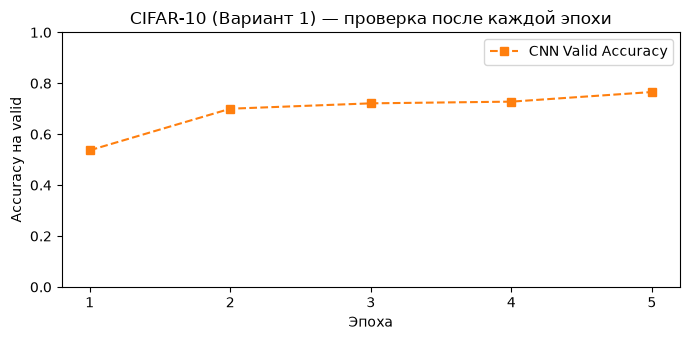

In [15]:
# Добавьте код графика accuracy на valid по эпохам.

history_df = pd.DataFrame(history, columns=["epoch", "train_loss", "valid_accuracy"])

plt.figure(figsize=(7, 3.5))
plt.plot(history_df.epoch, history_df.valid_accuracy, "s--", label="CNN Valid Accuracy", color="tab:orange")
plt.xticks(range(1, 6))
plt.ylim(0, 1)
plt.xlabel("Эпоха")
plt.ylabel("Accuracy на valid")
plt.title("CIFAR-10 (Вариант 1) — проверка после каждой эпохи")
plt.legend()
plt.tight_layout()
plt.show()


### 9. Получите ответы на test

Часть `test` содержит по 100 изображений каждого выбранного класса.
В этом проходе нет `backward()` и `step()`.
Параметры модели не изменяются.

In [16]:
# Получите ответы на тестовой выборке и сравните с верными ответами на основе метрик
# ОБЯЗАТЕЛЬНО model.eval()

cifar_cnn.eval()
predictions = []
answers = []

with torch.no_grad():
    for imgs, lbls in test_loader:
        logits = cifar_cnn(imgs.to(device))
        predictions.append(logits.argmax(dim=1).cpu())
        answers.append(lbls)

predictions = torch.cat(predictions).numpy()
answers = torch.cat(answers).numpy()

test_acc = accuracy_score(answers, predictions)
print("Объектов в test:", len(cifar_test))
print(f"Accuracy на test: {test_acc:.4f}")


Объектов в test: 900
Accuracy на test: 0.7844


### 10. Постройте матрицу ошибок и покажите три изображения

Для матрицы используйте `ConfusionMatrixDisplay.from_predictions`.
Передайте `answers`, `predictions`, `labels=range(3)` и `display_labels=class_names`.

Индексы первых ошибок находятся в `error_indices[:3]`.
Изображение с таким индексом можно получить как `test_data[index][0]`.
Для показа верните диапазон `0…1` выражением `image * 0.5 + 0.5` и переставьте оси через `permute(1, 2, 0)`.
Подпишите истинный класс и ответ модели.
Если ошибок меньше трёх, покажите все имеющиеся.

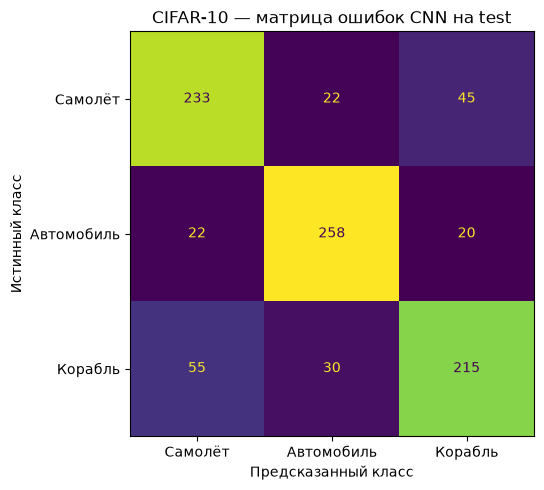

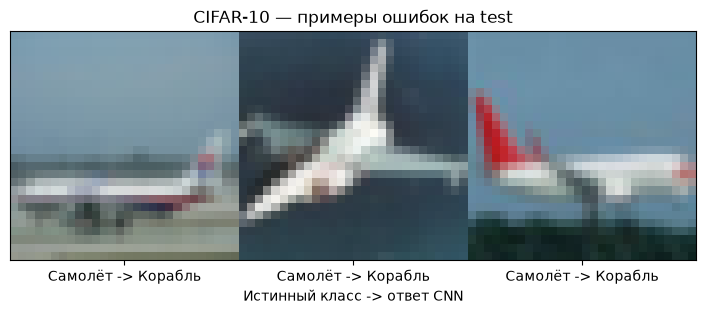

In [17]:
# Добавьте матрицу ошибок.
# Добавьте изображения с ошибочными ответами.

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    answers, predictions, labels=range(3), display_labels=class_names,
    ax=ax, colorbar=False
)
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
ax.set_title("CIFAR-10 — матрица ошибок CNN на test")
plt.tight_layout()
plt.show()

error_indices = np.flatnonzero(predictions != answers)[:3]

if len(error_indices) > 0:
    error_images = []
    captions = []
    
    for idx in error_indices:
        img_tensor, true_label = cifar_test[idx]
        pred_label = predictions[idx]
        
        img_arr = (img_tensor * 0.5 + 0.5).permute(1, 2, 0).numpy()
        error_images.append(img_arr)
        captions.append(f"{class_names[true_label]} -> {class_names[pred_label]}")
        
    strip = np.concatenate(error_images, axis=1)
    plt.figure(figsize=(8, 3))
    plt.imshow(strip)
    plt.xticks(np.arange(len(error_indices)) * 28 + 13.5, captions)
    plt.yticks([])
    plt.xlabel("Истинный класс -> ответ CNN")
    plt.title("CIFAR-10 — примеры ошибок на test")
    plt.tight_layout()
    plt.show()
else:
    print("На тестовой выборке ошибок нет.")
